# SVD of per-patient RBP activity over motor neuron differentiation

This notebook looks for the main **temporal patterns of RBP activity** over motor neuron differentiation (D0, D3, D7, D14, D22, D35) in control (WT) lines. For each 3'UTR region, it decomposes the per-patient matrix of CLIP Welch scores with a singular value decomposition (SVD). It then tests whether the main components change between D22 and D35, and lists the RBPs that drive them. The nuclear fraction, the cytoplasmic fraction and both together are analysed separately.

**Input**
- Per-patient Welch profiles of every CLIP dataset (`MN_diff/results/3UTR_analysis/CLIP_per_patient/analysis/welch_{proximal,distal}.csv`), merged with `scripts/clip/merge_welch_per_patient.py`. For each 50-nt bin from −1000 to +200 nt around the proximal (pPAS) or distal (dPAS) poly(A) site, the **Welch score** (`-log10(pval)*dPUD`, column `mean_score_lg10`) is the signed significance of the PUD difference linked to a CLIP site in that bin. There is one score per patient (`Replicate`), fraction, genotype and day. RNA modifications are not included.

**Regions** (distances in nt relative to the PAS)
- **Region 1** (`positive_proximal_region`): proximal isoform, [−350, −50]; maximum Welch score in the window, clipped at 0.
- **Region 2** (`negative_proximal_region`): proximal isoform, [0, 150]; minimum Welch score in the window, sign-flipped and clipped at 0 (depletion).
- **Region 3** (`positive_distal_region`): distal isoform, [−350, −50]; maximum of the sign-flipped Welch score, clipped at 0.

**Method** (same in every section)
1. Region matrix: CLIPs × `<Patient>_<Compartment>_<Genotype>_<Day>`, restricted to the WT columns of the section.
2. SVD of the raw matrix, which is **not centred**. Because of this, the first component mostly reflects each CLIP's average activity level. It is removed (rank-1 reconstruction subtracted) and the SVD is redone on the residual. From then on, **"PC1/Vt1, PC2/Vt2, …" refer to the residual**, i.e. they are components 2, 3, … of the original SVD.
3. Scree plots, before and after removing the first component. "Variance explained" is computed as sᵢ / Σs, the share of the singular-value sum, rather than sᵢ² / Σs².
4. The right singular vectors (`Vt`, one value per sample) are plotted against day: mean ± 95% CI across patients. The sign of each component is arbitrary, so only the *change* over time is meaningful, read together with the RBP loadings (`U`).
5. Day-to-day change of the first residual component for each patient (D3−D0, D7−D3, …).

`find_elbow` and the `df_pca` table are computed but not used. All figures are saved under `../Figures/Figure_RBP_SVD`, in one subfolder per section (`Nuclear_CTRL/`, `Cytoplasmic_CTRL/`, `Nuclear_and_Cytoplasmic_CTRL/`), with the region in the file name (`R1_upstream_pPAS`, `R2_downstream_pPAS`, `R3_upstream_dPAS`). Every saved file is listed with its legend in `../Figures/README.md`.

---

## Contents

Each section lists the files it saves, relative to `../Figures/Figure_RBP_SVD/`; `<region>` is `R1_upstream_pPAS`, `R2_downstream_pPAS` or `R3_upstream_dPAS`.

- [Setup and data loading](#setup)
- [Nuclear WT: SVD per region](#svd-nuclear-wt)
    - `Nuclear_CTRL/`: `scree_plot_<region>.pdf`, `scree_plot_<region>_first_component_removed.pdf`, `components_1to3_over_time_<region>.pdf`, `component1_change_from_previous_day_<region>.pdf`
- [Cytoplasmic WT: SVD per region](#svd-cyto-wt)
    - `Cytoplasmic_CTRL/`: same four files per region
- [Nuclear and cytoplasmic WT together: SVD per region](#svd-all-wt)
    - `Nuclear_and_Cytoplasmic_CTRL/`: `scree_plot_<region>.pdf`, `scree_plot_<region>_first_component_removed.pdf`, `component1_change_D14_to_D22_and_D22_to_D35_<region>.pdf`

<a id="setup"></a>
## Setup and data loading

Imports, output folder, colour palette, a sort key for the condition columns (fraction, then genotype, then day), and the per-patient proximal and distal Welch tables. These are concatenated into `df`, with VCP-R155C and VCP-R191Q pooled as "VCP". The last setup cell also defines the region boundaries; the commented-out lines hold earlier, wider windows.

In [1]:
import pandas as pd



from numpy.linalg import svd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import os
from scipy.stats import ttest_rel

from utrals.paths import PROJECT_DIR  # data locations outside the repository (paths.env)
from utrals.stats import find_elbow
from utrals import figures
figures.fix_random_seeds(0)  # fixed jitter and bootstrap confidence intervals: identical figures on every run


import matplotlib
matplotlib.rcParams["pdf.fonttype"] = 42
matplotlib.rcParams["ps.fonttype"] = 42

import warnings
warnings.filterwarnings("ignore")

In [2]:
figures_subfolder = "../Figures/Figure_RBP_SVD"
import os
from functools import partial

if not os.path.exists(f"{figures_subfolder}"):
    os.makedirs(f"{figures_subfolder}")

# save_figure saves a figure and lists it, with its legend, in ../Figures/README.md
from utrals import figures
save_figure = partial(figures.save_figure, notebook="Figure_RBP_SVD.ipynb")

# Region names used in the file names
region_labels = {"positive_proximal_region": "R1_upstream_pPAS",
                 "negative_proximal_region": "R2_downstream_pPAS",
                 "positive_distal_region": "R3_upstream_dPAS"}
region_legends = {"positive_proximal_region": "R1 (max Welch score in [-350, -50] nt upstream of the pPAS)",
                  "negative_proximal_region": "R2 (max of the sign-flipped Welch score in [0, +150] nt downstream of the pPAS, i.e. depletion)",
                  "positive_distal_region": "R3 (max of the sign-flipped Welch score in [-350, -50] nt upstream of the dPAS)"}
    

In [3]:
palette_condition = {"Cytoplasmic_WT": "#767676", 
                     "Nuclear_WT":  "#c5c5c5",
                     "Nuclear_VCP": "#d39eff",
                    "Cytoplasmic_VCP": "#8936ce"}

In [4]:



day_order = {'D0': 0, 'D3': 1, 'D7': 2, 'D14': 3, 'D22': 4, 'D35': 5}
compartment_order = {'Cytoplasmic': 0, 'Nuclear': 1}
vcp_order = {'WT': 0, 'VCP': 1}

def sort_key(col):
    parts = col.split('_')
    compartment = parts[0]
    vcp = parts[1]
    day = parts[2]
    return (compartment_order.get(compartment, 99), vcp_order.get(vcp, 99), day_order.get(day, 99))





In [5]:
welch_distal = pd.read_csv(f"{PROJECT_DIR}/MN_diff/results/3UTR_analysis/CLIP_per_patient/analysis/welch_distal.csv", index_col=0)
welch_proximal = pd.read_csv(f"{PROJECT_DIR}/MN_diff/results/3UTR_analysis/CLIP_per_patient/analysis/welch_proximal.csv", index_col=0)

In [6]:
df = pd.concat([welch_proximal, 
                welch_distal])
df.reset_index(drop=True, inplace=True)
df.replace({"Wildtype": "WT"}, inplace=True)
df.replace({"VCP-R155C": "VCP", "VCP-R191Q": 'VCP'}, inplace=True)


# positive_proximal_region = [-350, 100]
# negative_proximal_region = [0, 100]
# positive_distal_region = [-350, 100]

positive_proximal_region = [-350, -50]
negative_proximal_region = [0, 150]
positive_distal_region = [-350, -50]

<a id="svd-nuclear-wt"></a>
## Nuclear WT: SVD per region

SVD of the Nuclear WT columns (patients × days), run for each of the three regions. For each region, the cell produces:
- Scree plots before and after removing the first component: `scree_plot_<region>.pdf`, `scree_plot_<region>_first_component_removed.pdf`.
- The first three residual components (`Vt1`–`Vt3`) over days, with a **paired t-test D22 vs D35** across patients, since the same lines are sampled at both days. P-values are uncorrected. Saved as `components_1to3_over_time_<region>.pdf`.
- The change of `Vt1` from the previous day, per patient: `component1_change_from_previous_day_<region>.pdf`.
- Printed output: whether mean `Vt1` goes down or up from D22 to D35, the 10 CLIPs with the most negative (if it goes down) or most positive (if it goes up) loading on `U1`, and whether these CLIPs' mean raw scores decrease or increase from D22 to D35. A short interpretation follows (promotion of the proximal or the distal isoform).

All files are saved in `Nuclear_CTRL/`.

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


Region: positive_proximal_region, min: 0.0, max: 41.889443473647184


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


We observe an increase in PC1 scores from D22 to D35
Top 10 RBPs contributing positively to PC1:
['SRSF1_2_HepG2', 'SRSF9_1_HepG2', 'RBFOX2_1_HepG2', 'TDP43-20161012_iCLIP', 'PPIG_2_HepG2', 'SRSF1_1_HepG2', 'PRPF8_2_HepG2', 'PRPF8_1_HepG2', 'PPIG_1_HepG2', 'CSTF2T_2_HepG2']
The top RBPs show an increase in their mean scores from D22 to D35.
The RBPs contributing the most to PC1 indicate promotion of the proximal


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


...

Top 10 RBPs contributing negatively to PC1:
We observe a decrease in PC1 scores from D22 to D35
['all-Celf4-FlpIn293-_iCLIP', 'all-HuR-FlpIn293-_iCLIP', 'all-TIAL1-Hela-_iCLIP', 'hnrnpc-bestof_iCLIP', 'FUBP3_1_HepG2', 'all-TIA1-Hela-_iCLIP', 'all-IGF2BP2-Hela-_iCLIP', 'all-CGI99-FlpIn293-_iCLIP', 'all-eIF4E-FlpIn293-_iCLIP', 'FUBP3_2_HepG2']
The top RBPs show an increase in their mean scores from D22 to D35.
The RBPs contributing the most to PC1 indicate promotion of the distal


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


Region: positive_distal_region, min: 0.0, max: 132.80922738184478


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


We observe an increase in PC1 scores from D22 to D35
Top 10 RBPs contributing positively to PC1:
['all-Celf4-FlpIn293-_iCLIP', 'all-TIA1-Hela-_iCLIP', 'FUBP3_1_HepG2', 'FUBP3_2_HepG2', 'all-TIAL1-Hela-_iCLIP', 'all-eIF4E-FlpIn293-_iCLIP', 'all-Celf2-293Flp-_iCLIP', 'KHSRP_1_K652', 'PUM2_1_K652', 'all-HuR-FlpIn293-_iCLIP']
The top RBPs show an increase in their mean scores from D22 to D35.
The RBPs contributing the most to PC1 indicate promotion of the distal


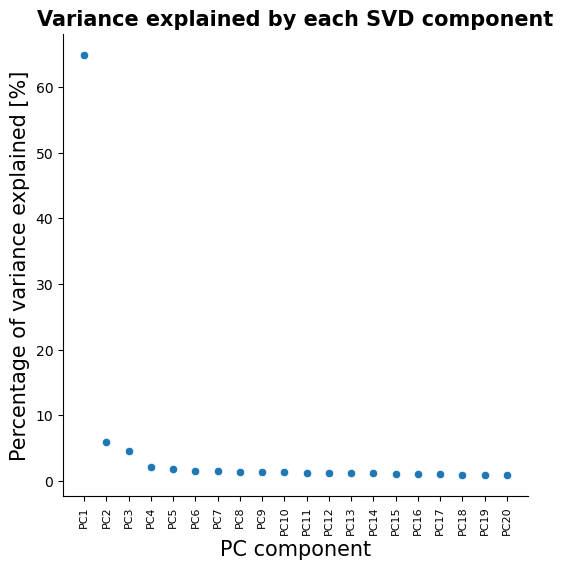

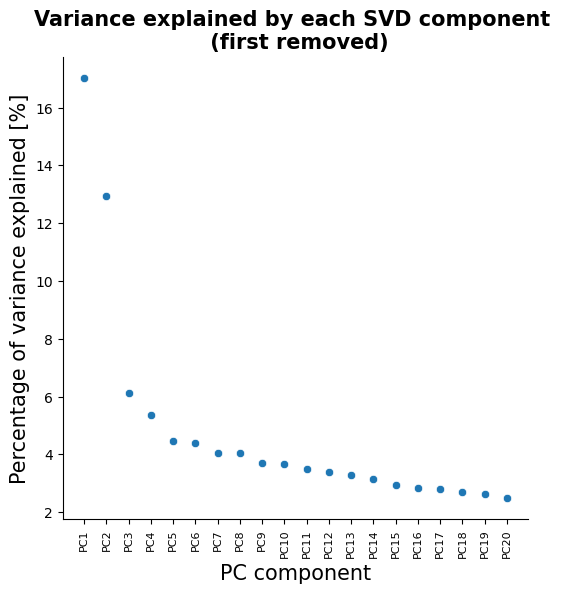

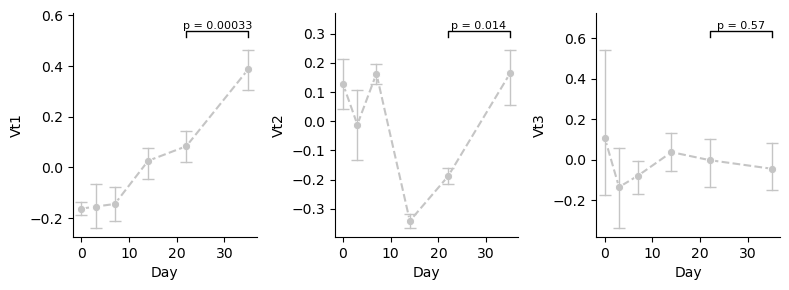

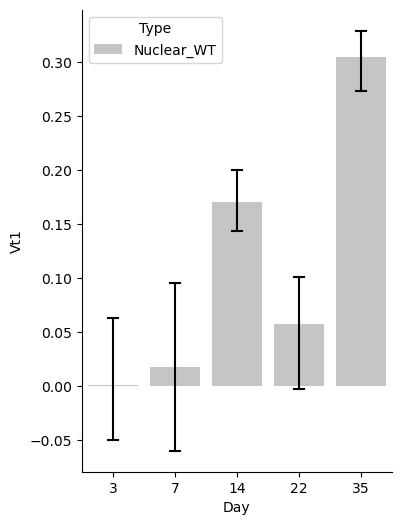

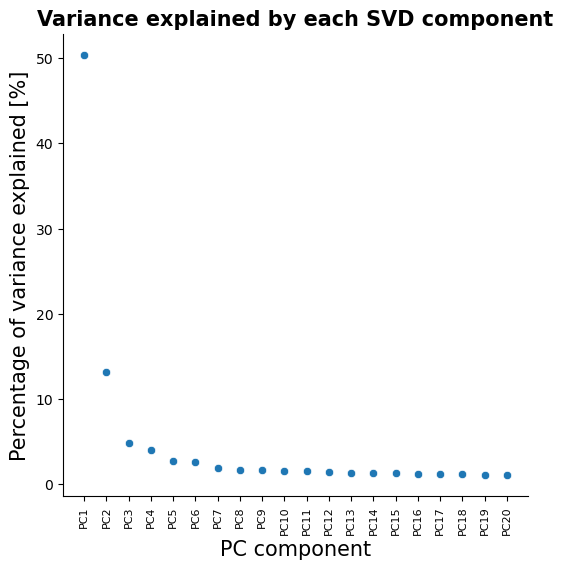

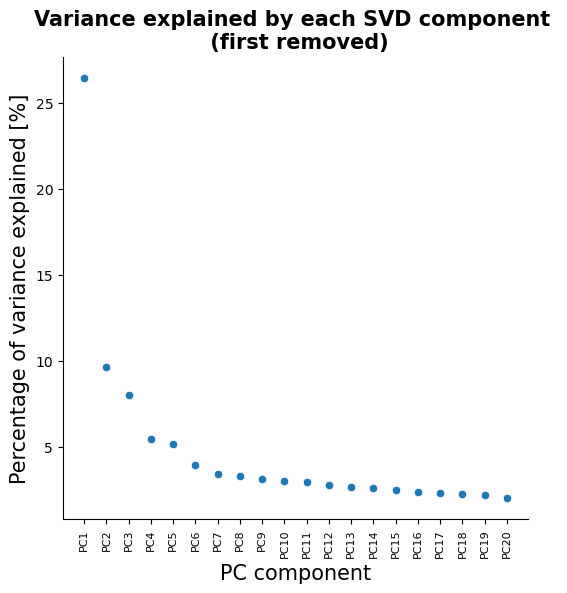

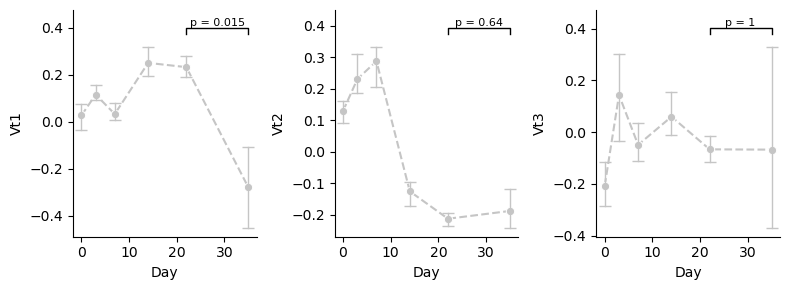

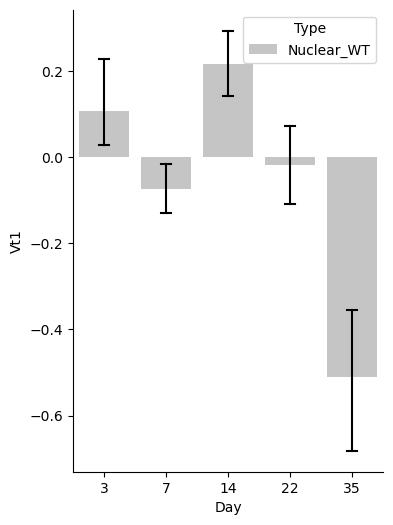

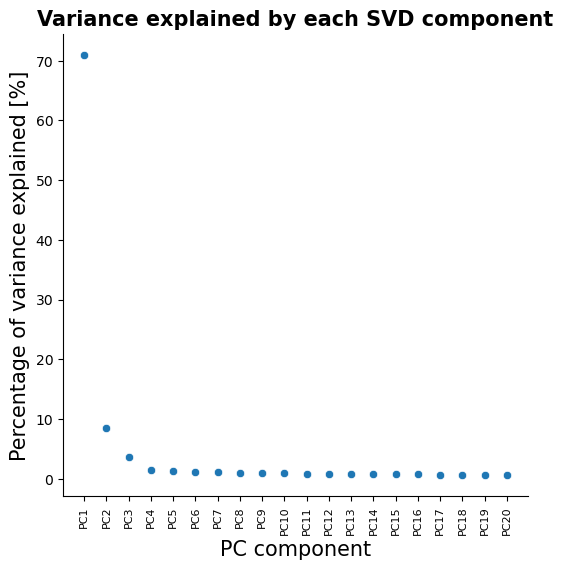

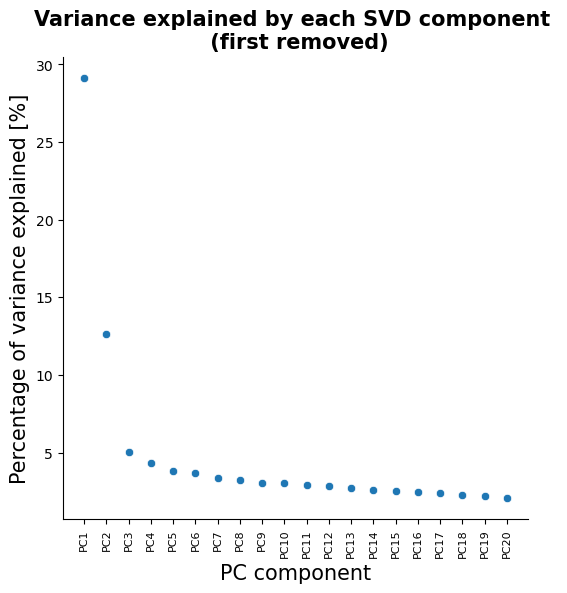

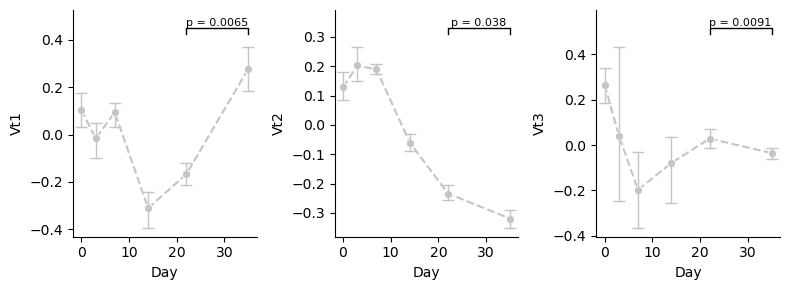

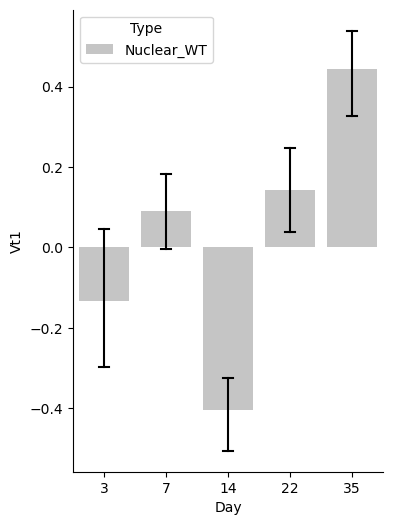

In [7]:
# Region1, 2 & 3: positive_proximal_region, negative_proximal_region, positive_distal_region

for region_name, region in zip(["positive_proximal_region", "negative_proximal_region", "positive_distal_region"], 
                               [positive_proximal_region, negative_proximal_region, positive_distal_region]):


    df_region = df[(df['dist'] >= region[0]) & (df['dist'] <= region[1]) & (df['Isoform'] == "Proximal 3'UTR Isoform")]
    df_int = df_region.loc[df_region.groupby(["Replicate", "Compartment", "CLIP", "VCP", "Day"])["mean_score_lg10"].idxmax()]
    # Create matrix with RBPs in rows and Compartment_VCP_Day combinations in columns
    df_int['Condition'] = df_int['Replicate'] + '_' + df_int['Compartment'] + '_' + df_int['VCP'] + '_' + df_int['Day']
    
    if region_name == "positive_proximal_region":
        df_int["mean_score_lg10"] = df_int["mean_score_lg10"].clip(lower=0)
        matrix = df_int.pivot(index='CLIP', columns='Condition', values='mean_score_lg10')

        
    elif region_name == "negative_proximal_region":
        # Negate first, then take the max: strongest depletion in the window
        df_region["mean_score_lg10"] = - df_region["mean_score_lg10"]
        df_int = df_region.loc[df_region.groupby(["Replicate", "Compartment", "CLIP", "VCP", "Day"])["mean_score_lg10"].idxmax()]
        df_int['Condition'] = df_int['Replicate'] + '_' + df_int['Compartment'] + '_' + df_int['VCP'] + '_' + df_int['Day']
        df_int["mean_score_lg10"] = df_int["mean_score_lg10"].clip(lower=0)
        matrix = df_int.pivot(index='CLIP', columns='Condition', values='mean_score_lg10')

        matrix_2 = matrix.copy()
    
    else:
        df_region = df[(df['dist'] >= region[0]) & (df['dist'] <= region[1]) & (df['Isoform'] == "Distal 3'UTR Isoform")]
        df_region["mean_score_lg10"] = -df_region["mean_score_lg10"]
        df_int = df_region.loc[df_region.groupby(["Replicate", "Compartment", "CLIP", "VCP", "Day"])["mean_score_lg10"].apply(lambda x: x.idxmax())]
        df_int['Condition'] = df_int['Replicate'] + '_' + df_int['Compartment'] + '_' + df_int['VCP'] + '_' + df_int['Day']
        df_int["mean_score_lg10"] = df_int["mean_score_lg10"].clip(lower=0)
        matrix = df_int.pivot(index='CLIP', columns='Condition', values='mean_score_lg10')

    print(f"Region: {region_name}, min: {matrix.min().min()}, max: {matrix.max().max()}")
    matrix_WT = matrix[[col for col in matrix.columns if "Nuclear_WT" in col]]
    
    
    U, s, Vt = svd(matrix_WT, full_matrices=True)


    explained_variance = s*100 / s.sum()

    df_var = pd.DataFrame(explained_variance, index=['PC'+str(i+1) for i in range(len(explained_variance))])[:20]

    plt.figure(figsize=(6, 6))
    sns.scatterplot(x=df_var.index, y=df_var[0])
    plt.xlabel('PC component', fontsize=15)
    plt.ylabel('Percentage of variance explained [%]', fontsize=15)
    plt.title('Variance explained by each SVD component', weight='bold', fontsize=15)
    sns.despine()
    plt.xticks(rotation=90, fontsize=8);
    plt.legend().remove()
    

    save_figure(f"{figures_subfolder}/Nuclear_CTRL/scree_plot_{region_labels[region_name]}.pdf",
                legend=f"SVD of the per-patient Welch-score matrix (CLIP datasets x nuclear CTRL samples (patients x days)) for {region_legends[region_name]}, scores clipped at 0. The matrix is not centred, so the first component (mostly the mean binding level) is removed and the SVD redone on the residual; 'PC1/Vt1' after removal = component 2 of the original SVD. Scree plot: share of each singular value in the sum of singular values (s_i / sum(s), first 20 components), before removing the first component.")
    ## Removing first component
    X_without_PC1 = matrix_WT - np.dot(np.array([U[:, 0]*s[0]]).T, np.array([Vt[0]]))

    # Do the SVD again
    U_w1, s_w1, Vt_w1 = svd(X_without_PC1, full_matrices=False)

    explained_variance_w1 = s_w1*100 / s_w1.sum()
    df_var_w1 = pd.DataFrame(explained_variance_w1, index=['PC'+str(i+1) for i in range(len(explained_variance_w1))])[:20]
    plt.figure(figsize=(6, 6))
    sns.scatterplot(x=df_var_w1.index, y=df_var_w1[0])
    plt.xlabel('PC component', fontsize=15)
    plt.ylabel('Percentage of variance explained [%]', fontsize=15)
    plt.title('Variance explained by each SVD component \n (first removed)', weight='bold', fontsize=15)
    sns.despine()
    plt.xticks(rotation=90, fontsize=8);
    plt.legend().remove()
    save_figure(f"{figures_subfolder}/Nuclear_CTRL/scree_plot_{region_labels[region_name]}_first_component_removed.pdf",
                legend=f"SVD of the per-patient Welch-score matrix (CLIP datasets x nuclear CTRL samples (patients x days)) for {region_legends[region_name]}, scores clipped at 0. The matrix is not centred, so the first component (mostly the mean binding level) is removed and the SVD redone on the residual; 'PC1/Vt1' after removal = component 2 of the original SVD. Scree plot: share of each singular value in the sum of singular values (s_i / sum(s), first 20 components), after removing the first component.")

    elbow_idx, distances = find_elbow(explained_variance)
    elbow_idx_w1, distances_w1 = find_elbow(explained_variance_w1)
    n_pcs = elbow_idx_w1 + 1
    
    df_pca = pd.DataFrame((U_w1[:, :len(s_w1)] * s_w1)[:, :len(s_w1)], index=matrix_WT.index, columns=['PC'+str(i+1) for i in range(len(s_w1))])
    ordered_columns = sorted(matrix_WT.columns, key=sort_key)
    df_pca = df_pca.merge(matrix_WT[ordered_columns], left_index=True, right_index=True)
    
    df_Vt = pd.DataFrame(Vt_w1.T, index=matrix_WT.columns, columns=['Vt'+str(i+1) for i in range(Vt_w1.shape[0])])

    df_Vt['Mutation'] = df_Vt.index.str.split('_').str[2]
    df_Vt['Day'] = df_Vt.index.str.split('_D').str[1]
    df_Vt['Day'] = df_Vt['Day'].astype(int)
    df_Vt['Compartment'] = df_Vt.index.str.split('_').str[1]
    df_Vt['Type'] = df_Vt['Compartment'] + '_' + df_Vt['Mutation']
    
    pvalues = []

    plt.figure(figsize=(8, 3))
    for i in range(3):
        plt.subplot(1, 3, i+1)
        sns.lineplot(
            data=df_Vt,
            x='Day',
            y='Vt'+str(i+1),
            hue='Type',
            palette=palette_condition,
            marker='o',
            linestyle='dashed',
            err_style='bars',         # <-- draw CI as error bars instead of band
            ci=95,                    # change CI level if desired
            err_kws={'capsize': 4, 'elinewidth': 1}
        )
        sns.despine()
        if i != 23:
            plt.legend().remove()
        else:
            plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
            
        # Paired t-test: the same patients are sampled at D22 and D35
        df_d22_d35 = df_Vt[(df_Vt["Type"] == "Nuclear_WT") & (df_Vt['Day'].isin([22, 35]))].copy()
        df_d22_d35['Patient'] = df_d22_d35.index.str.split('_').str[0]
        paired = df_d22_d35.pivot(index='Patient', columns='Day', values='Vt'+str(i+1)).dropna()
        Q, p = ttest_rel(paired[22], paired[35])
        
        pvalues.append(p)
        
        ax = plt.gca()
        y_min, y_max = ax.get_ylim()
        y = y_max + 0.02 * (y_max - y_min)
        h = 0.03 * (y_max - y_min)
        ax.plot([22, 22, 35, 35], [y, y + h, y + h, y], color='black', linewidth=1)
        ax.text(28.5, y + h, f"p = {p:.2g}", ha='center', va='bottom', fontsize=8)
        ax.set_ylim(y_min, y + 4 * h)
    plt.tight_layout()
    save_figure(f"{figures_subfolder}/Nuclear_CTRL/components_1to3_over_time_{region_labels[region_name]}.pdf",
                legend=f"SVD of the per-patient Welch-score matrix (CLIP datasets x nuclear CTRL samples (patients x days)) for {region_legends[region_name]}, scores clipped at 0. The matrix is not centred, so the first component (mostly the mean binding level) is removed and the SVD redone on the residual; 'PC1/Vt1' after removal = component 2 of the original SVD. First three residual components (Vt1-Vt3, one value per sample) over days: mean and 95% CI across patients. Bracket: paired t-test D22 vs D35 across patients (uncorrected). The sign of a component is arbitrary.")
    
    
    df_Vt_diff = df_Vt.copy()
    df_Vt_diff['patient'] = df_Vt_diff.index.str.split('_').str[0]

    vt_cols = [col for col in df_Vt.columns if col.startswith('Vt')]

    df_Vt_diff = df_Vt.copy()
    df_Vt_diff['Patient'] = df_Vt_diff.index.str.split('_').str[0]

    # Sort by patient and day so diff() computes consecutive-day differences
    df_Vt_diff = df_Vt_diff.sort_values(['Patient', 'Day'])

    # D3-D0, D7-D3, D14-D7, D22-D14, D35-D22 (D0 becomes NaN)
    df_Vt_diff[vt_cols] = df_Vt_diff.groupby('Patient')[vt_cols].diff()

    # df_Vt_diff.drop(columns=['Patient'], inplace=True)

    df_U = pd.DataFrame(U_w1, index=matrix_WT.index, columns=['U'+str(i+1) for i in range(U_w1.shape[1])])
    

        
    df_Vt_diff = df_Vt_diff[df_Vt_diff['Day'] != 0]
    plt.figure(figsize=(4, 6))
    sns.barplot(
        data=df_Vt_diff,
        x='Day',
        y='Vt1',
        hue='Type',
        palette=palette_condition,
                    capsize=0.15,
                errcolor="black",
                errwidth=1.5,

    )
    sns.despine()
    
    save_figure(f"{figures_subfolder}/Nuclear_CTRL/component1_change_from_previous_day_{region_labels[region_name]}.pdf",
                legend=f"SVD of the per-patient Welch-score matrix (CLIP datasets x nuclear CTRL samples (patients x days)) for {region_legends[region_name]}, scores clipped at 0. The matrix is not centred, so the first component (mostly the mean binding level) is removed and the SVD redone on the residual; 'PC1/Vt1' after removal = component 2 of the original SVD. Change of the first residual component (Vt1) from the previous day for each patient (D3-D0, ..., D35-D22): mean and 95% CI across patients.")
    
    df_U = pd.DataFrame(U_w1, index=matrix_WT.index, columns=['U'+str(i+1) for i in range(U_w1.shape[1])])

    if (df_Vt.groupby(["Day"]).mean().loc[35] - df_Vt.groupby(["Day"]).mean().loc[22])['Vt1'] < 0: # looking for the RBPs contributing negatively to PC1
        top_idxs = df_U['U1'].sort_values(ascending=True).head(10)
        print("Top 10 RBPs contributing negatively to PC1:")
        print("We observe a decrease in PC1 scores from D22 to D35")

        print(top_idxs.index.tolist())
    else: # looking for the RBPs contributing positively to PC1
        top_idxs = df_U['U1'].sort_values(ascending=False).head(10)
        print("We observe an increase in PC1 scores from D22 to D35")
        print("Top 10 RBPs contributing positively to PC1:")
        print(top_idxs.index.tolist())
        
    sub = matrix_WT.loc[top_idxs.index]

    diffs = []
    d22 = sub[[f"{patient}_Nuclear_WT_D22" for patient in df_Vt_diff['Patient'].unique()]].mean(axis=1)
    d35 = sub[[f"{patient}_Nuclear_WT_D35" for patient in df_Vt_diff['Patient'].unique()]].mean(axis=1)
    total_diff = d35 - d22

    if total_diff.mean() < 0:
        print("The top RBPs show a decrease in their mean scores from D22 to D35.")
        if region_name == "positive_proximal_region":
            print("The RBPs contributing the most to PC1 indicate promotion of the distal")
        else:
            print("The RBPs contributing the most to PC1 indicate promotion of the proximal")
    else:
        print("The top RBPs show an increase in their mean scores from D22 to D35.")
        if region_name == "positive_proximal_region":
            print("The RBPs contributing the most to PC1 indicate promotion of the proximal")
        else:
            print("The RBPs contributing the most to PC1 indicate promotion of the distal")

    

In [8]:
matrix_2.sort_values(by="CTRL1_Nuclear_WT_D35")

Condition,CTRL1_Cytoplasmic_WT_D0,CTRL1_Cytoplasmic_WT_D14,CTRL1_Cytoplasmic_WT_D22,CTRL1_Cytoplasmic_WT_D3,CTRL1_Nuclear_WT_D0,CTRL1_Nuclear_WT_D14,CTRL1_Nuclear_WT_D22,CTRL1_Nuclear_WT_D35,CTRL1_Nuclear_WT_D7,CTRL3_Cytoplasmic_WT_D0,...,MUT4_Cytoplasmic_VCP_D22,MUT4_Cytoplasmic_VCP_D3,MUT4_Cytoplasmic_VCP_D35,MUT4_Cytoplasmic_VCP_D7,MUT4_Nuclear_VCP_D0,MUT4_Nuclear_VCP_D14,MUT4_Nuclear_VCP_D22,MUT4_Nuclear_VCP_D3,MUT4_Nuclear_VCP_D35,MUT4_Nuclear_VCP_D7
CLIP,,,,,,,,,,,,,,,,,,,,,
SRSF1_1_HepG2,0.815641,1.863058,1.531569,0.552513,0.133232,1.360491,0.990527,0.000000,0.194787,1.158987,...,2.479232,1.595054,1.008600,1.065358,0.083144,0.939823,0.720611,0.664089,4.810268,0.102404
RBM15_1_HepG2,2.257343,4.862696,3.136773,1.773479,1.039965,2.761529,2.147682,0.000000,1.913293,2.709931,...,3.328392,4.042207,2.314478,2.755882,1.084779,1.694583,2.258310,1.323834,7.215728,1.536078
RBFOX2_1_HepG2,0.469449,1.276556,1.080531,0.014389,0.017358,1.507992,1.054336,0.000000,0.000000,1.188467,...,1.344817,1.105279,0.822402,0.464563,0.000000,1.412754,0.752210,0.353188,1.024371,0.000000
SRSF9_1_HepG2,1.707023,1.949635,3.835941,1.616875,0.311510,1.709678,1.046124,0.000000,0.654468,2.846418,...,3.177205,2.120670,1.291897,2.579823,0.289611,1.191453,1.128961,1.141476,2.738715,0.616939
SRSF9_2_HepG2,1.711024,2.200419,1.091818,1.266386,1.053561,1.421527,0.585714,0.000000,1.044181,1.154295,...,0.663973,1.326386,0.404027,0.864232,0.931687,0.749785,1.450364,0.732833,5.709253,0.694659
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
all-TIAL1-Hela-_iCLIP,0.311662,2.177626,0.197121,3.428943,2.279942,1.085045,1.472541,14.299887,6.039655,2.091769,...,1.123959,2.096951,0.889720,1.610061,2.815239,0.531568,2.518112,2.478732,25.633640,5.370180
FAM120A_1_K652,6.502647,11.868505,8.170955,8.764696,7.264450,9.804272,11.786888,17.551793,11.334471,7.300217,...,10.344624,7.634759,9.038587,7.028192,7.395916,8.496642,12.916427,7.573512,34.342675,7.972386
all-HuR-FlpIn293-_iCLIP,0.000000,1.076613,0.000000,1.870982,1.879750,1.016347,2.183837,19.767767,4.688360,0.879030,...,0.209213,0.497677,0.144878,1.566541,2.571140,0.072984,2.473824,0.984714,16.633561,4.615758


<a id="svd-cyto-wt"></a>
## Cytoplasmic WT: SVD per region

Same analysis as the nuclear section, on the Cytoplasmic WT columns: scree plots, `Vt1`–`Vt3` over days with the paired D22 vs D35 t-test, and the day-to-day change of `Vt1`. Unlike the nuclear section, the top-contributing RBPs are not printed. All files are saved in `Cytoplasmic_CTRL/`, with the same file names.

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


Region: positive_proximal_region, min: 0.0, max: 41.889443473647184


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


Region: negative_proximal_region, min: 0.0, max: 49.30495049714422


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


Region: positive_distal_region, min: 0.0, max: 132.80922738184478


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


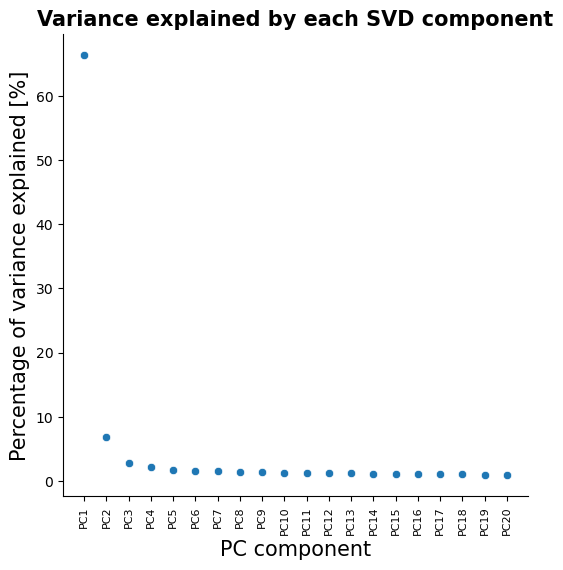

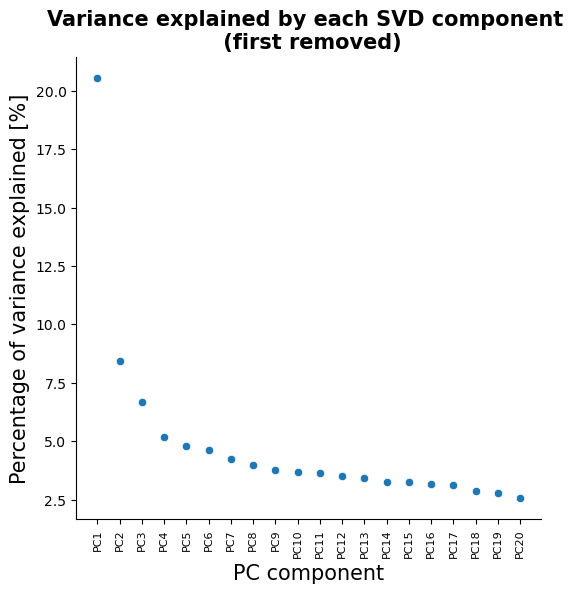

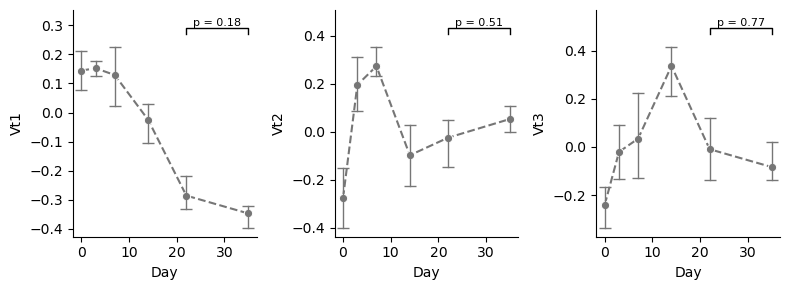

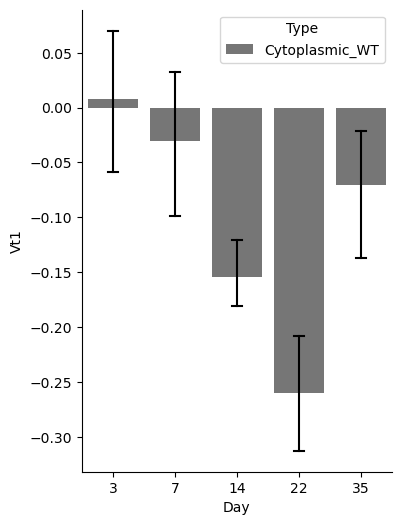

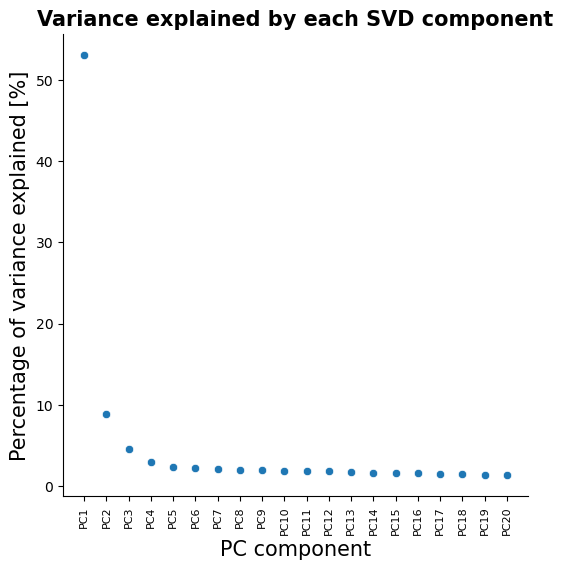

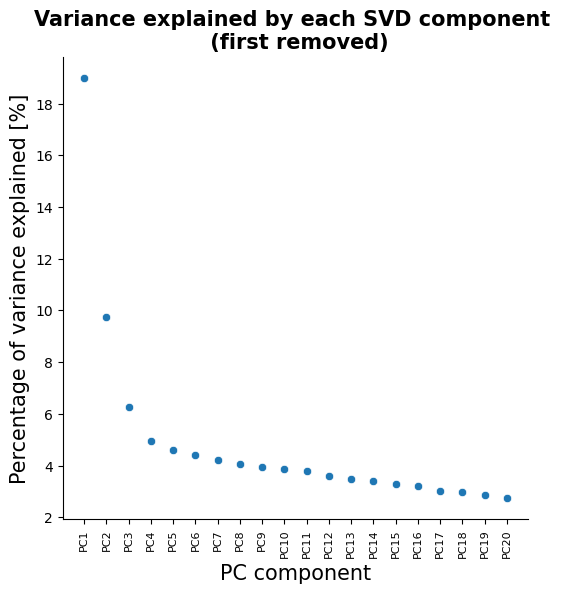

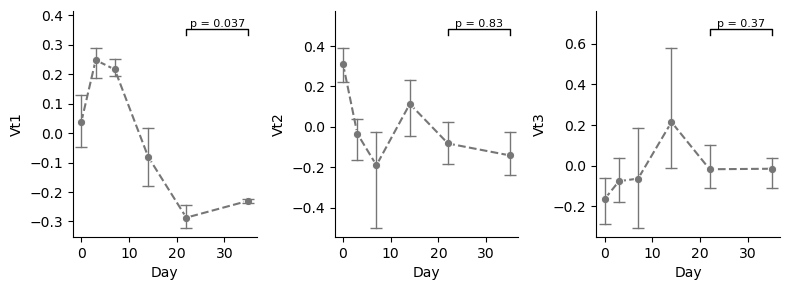

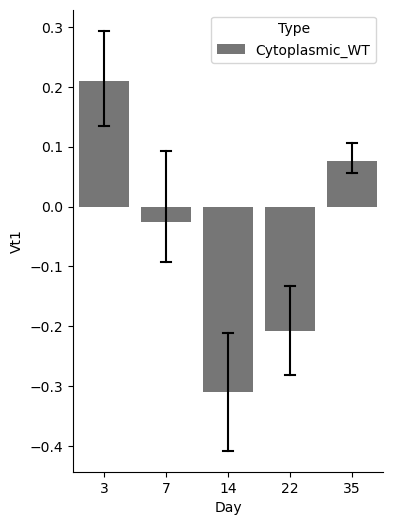

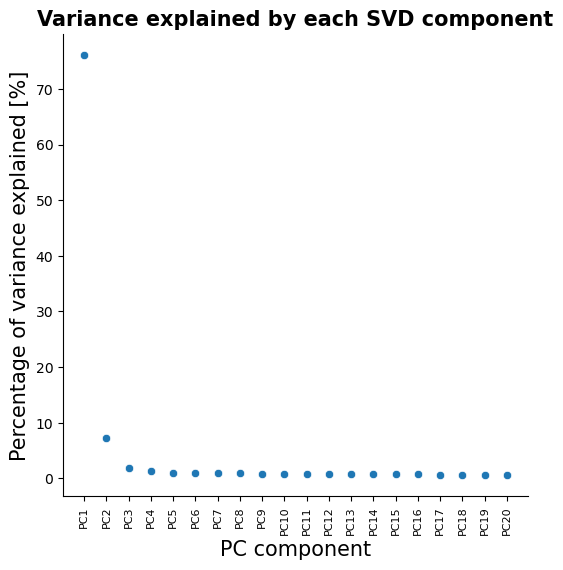

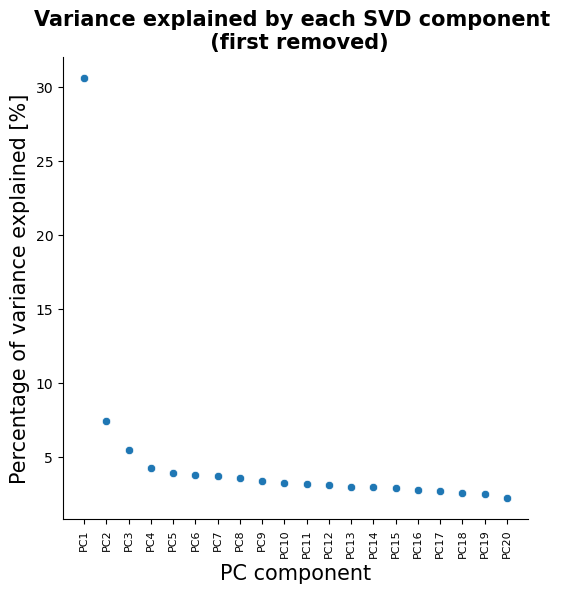

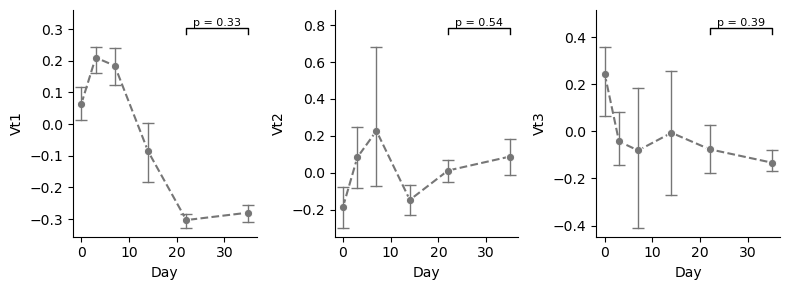

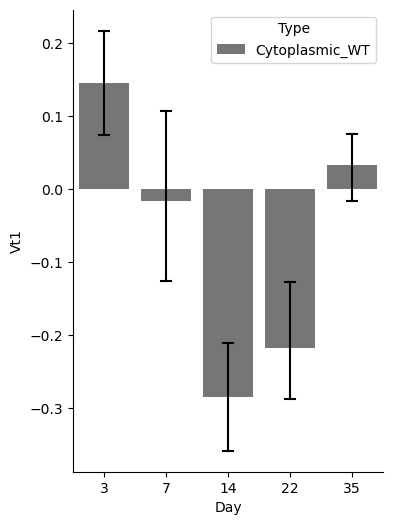

In [9]:
for region_name, region in zip(["positive_proximal_region", "negative_proximal_region", "positive_distal_region"], 
                               [positive_proximal_region, negative_proximal_region, positive_distal_region]):


    df_region = df[(df['dist'] >= region[0]) & (df['dist'] <= region[1]) & (df['Isoform'] == "Proximal 3'UTR Isoform")]
    df_int = df_region.loc[df_region.groupby(["Replicate", "Compartment", "CLIP", "VCP", "Day"])["mean_score_lg10"].idxmax()]
    # Create matrix with RBPs in rows and Compartment_VCP_Day combinations in columns
    df_int['Condition'] = df_int['Replicate'] + '_' + df_int['Compartment'] + '_' + df_int['VCP'] + '_' + df_int['Day']
    
    if region_name == "positive_proximal_region":
        df_int["mean_score_lg10"] = df_int["mean_score_lg10"].clip(lower=0)
        matrix = df_int.pivot(index='CLIP', columns='Condition', values='mean_score_lg10')

        
    elif region_name == "negative_proximal_region":
        # Negate first, then take the max: strongest depletion in the window
        df_region["mean_score_lg10"] = - df_region["mean_score_lg10"]
        df_int = df_region.loc[df_region.groupby(["Replicate", "Compartment", "CLIP", "VCP", "Day"])["mean_score_lg10"].idxmax()]
        df_int['Condition'] = df_int['Replicate'] + '_' + df_int['Compartment'] + '_' + df_int['VCP'] + '_' + df_int['Day']
        df_int["mean_score_lg10"] = df_int["mean_score_lg10"].clip(lower=0)
        matrix = df_int.pivot(index='CLIP', columns='Condition', values='mean_score_lg10')

    
    else:
        df_region = df[(df['dist'] >= region[0]) & (df['dist'] <= region[1]) & (df['Isoform'] == "Distal 3'UTR Isoform")]
        df_region["mean_score_lg10"] = -df_region["mean_score_lg10"]
        df_int = df_region.loc[df_region.groupby(["Replicate", "Compartment", "CLIP", "VCP", "Day"])["mean_score_lg10"].apply(lambda x: x.idxmax())]
        df_int['Condition'] = df_int['Replicate'] + '_' + df_int['Compartment'] + '_' + df_int['VCP'] + '_' + df_int['Day']
        df_int["mean_score_lg10"] = df_int["mean_score_lg10"].clip(lower=0)
        matrix = df_int.pivot(index='CLIP', columns='Condition', values='mean_score_lg10')

    print(f"Region: {region_name}, min: {matrix.min().min()}, max: {matrix.max().max()}")
    matrix_Cyto_WT = matrix[[col for col in matrix.columns if "Cytoplasmic_WT" in col]]


    U, s, Vt = svd(matrix_Cyto_WT, full_matrices=True)


    explained_variance = s*100 / s.sum()

    df_var = pd.DataFrame(explained_variance, index=['PC'+str(i+1) for i in range(len(explained_variance))])[:20]

    plt.figure(figsize=(6, 6))
    sns.scatterplot(x=df_var.index, y=df_var[0])
    plt.xlabel('PC component', fontsize=15)
    plt.ylabel('Percentage of variance explained [%]', fontsize=15)
    plt.title('Variance explained by each SVD component', weight='bold', fontsize=15)
    sns.despine()
    plt.xticks(rotation=90, fontsize=8);
    plt.legend().remove()


    save_figure(f"{figures_subfolder}/Cytoplasmic_CTRL/scree_plot_{region_labels[region_name]}.pdf",
                legend=f"SVD of the per-patient Welch-score matrix (CLIP datasets x cytoplasmic CTRL samples (patients x days)) for {region_legends[region_name]}, scores clipped at 0. The matrix is not centred, so the first component (mostly the mean binding level) is removed and the SVD redone on the residual; 'PC1/Vt1' after removal = component 2 of the original SVD. Scree plot: share of each singular value in the sum of singular values (s_i / sum(s), first 20 components), before removing the first component.")
    ## Removing first component
    X_without_PC1 = matrix_Cyto_WT - np.dot(np.array([U[:, 0]*s[0]]).T, np.array([Vt[0]]))

    # Do the SVD again
    U_w1, s_w1, Vt_w1 = svd(X_without_PC1, full_matrices=False)

    explained_variance_w1 = s_w1*100 / s_w1.sum()
    df_var_w1 = pd.DataFrame(explained_variance_w1, index=['PC'+str(i+1) for i in range(len(explained_variance_w1))])[:20]
    plt.figure(figsize=(6, 6))
    sns.scatterplot(x=df_var_w1.index, y=df_var_w1[0])
    plt.xlabel('PC component', fontsize=15)
    plt.ylabel('Percentage of variance explained [%]', fontsize=15)
    plt.title('Variance explained by each SVD component \n (first removed)', weight='bold', fontsize=15)
    sns.despine()
    plt.xticks(rotation=90, fontsize=8);
    plt.legend().remove()
    save_figure(f"{figures_subfolder}/Cytoplasmic_CTRL/scree_plot_{region_labels[region_name]}_first_component_removed.pdf",
                legend=f"SVD of the per-patient Welch-score matrix (CLIP datasets x cytoplasmic CTRL samples (patients x days)) for {region_legends[region_name]}, scores clipped at 0. The matrix is not centred, so the first component (mostly the mean binding level) is removed and the SVD redone on the residual; 'PC1/Vt1' after removal = component 2 of the original SVD. Scree plot: share of each singular value in the sum of singular values (s_i / sum(s), first 20 components), after removing the first component.")

    elbow_idx, distances = find_elbow(explained_variance)
    elbow_idx_w1, distances_w1 = find_elbow(explained_variance_w1)
    n_pcs = elbow_idx_w1 + 1

    df_pca = pd.DataFrame((U_w1[:, :len(s_w1)] * s_w1)[:, :len(s_w1)], index=matrix_Cyto_WT.index, columns=['PC'+str(i+1) for i in range(len(s_w1))])
    ordered_columns = sorted(matrix_Cyto_WT.columns, key=sort_key)
    df_pca = df_pca.merge(matrix_Cyto_WT[ordered_columns], left_index=True, right_index=True)

    df_Vt = pd.DataFrame(Vt_w1.T, index=matrix_Cyto_WT.columns, columns=['Vt'+str(i+1) for i in range(Vt_w1.shape[0])])

    df_Vt['Mutation'] = df_Vt.index.str.split('_').str[2]
    df_Vt['Day'] = df_Vt.index.str.split('_D').str[1]
    df_Vt['Day'] = df_Vt['Day'].astype(int)
    df_Vt['Compartment'] = df_Vt.index.str.split('_').str[1]
    df_Vt['Type'] = df_Vt['Compartment'] + '_' + df_Vt['Mutation']

    pvalues = []

    plt.figure(figsize=(8, 3))
    for i in range(3):
        plt.subplot(1, 3, i+1)
        sns.lineplot(
            data=df_Vt,
            x='Day',
            y='Vt'+str(i+1),
            hue='Type',
            palette=palette_condition,
            marker='o',
            linestyle='dashed',
            err_style='bars',         # <-- draw CI as error bars instead of band
            ci=95,                    # change CI level if desired
            err_kws={'capsize': 4, 'elinewidth': 1}
        )
        sns.despine()
        if i != 23:
            plt.legend().remove()
        else:
            plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
            
        # Paired t-test: the same patients are sampled at D22 and D35
        df_d22_d35 = df_Vt[(df_Vt["Type"] == "Cytoplasmic_WT") & (df_Vt['Day'].isin([22, 35]))].copy()
        df_d22_d35['Patient'] = df_d22_d35.index.str.split('_').str[0]
        paired = df_d22_d35.pivot(index='Patient', columns='Day', values='Vt'+str(i+1)).dropna()
        Q, p = ttest_rel(paired[22], paired[35])
        
        pvalues.append(p)
        
        ax = plt.gca()
        y_min, y_max = ax.get_ylim()
        y = y_max + 0.02 * (y_max - y_min)
        h = 0.03 * (y_max - y_min)
        ax.plot([22, 22, 35, 35], [y, y + h, y + h, y], color='black', linewidth=1)
        ax.text(28.5, y + h, f"p = {p:.2g}", ha='center', va='bottom', fontsize=8)
        ax.set_ylim(y_min, y + 4 * h)
    plt.tight_layout()
    save_figure(f"{figures_subfolder}/Cytoplasmic_CTRL/components_1to3_over_time_{region_labels[region_name]}.pdf",
                legend=f"SVD of the per-patient Welch-score matrix (CLIP datasets x cytoplasmic CTRL samples (patients x days)) for {region_legends[region_name]}, scores clipped at 0. The matrix is not centred, so the first component (mostly the mean binding level) is removed and the SVD redone on the residual; 'PC1/Vt1' after removal = component 2 of the original SVD. First three residual components (Vt1-Vt3, one value per sample) over days: mean and 95% CI across patients. Bracket: paired t-test D22 vs D35 across patients (uncorrected). The sign of a component is arbitrary.")


    df_Vt_diff = df_Vt.copy()
    df_Vt_diff['patient'] = df_Vt_diff.index.str.split('_').str[0]

    vt_cols = [col for col in df_Vt.columns if col.startswith('Vt')]

    df_Vt_diff = df_Vt.copy()
    df_Vt_diff['Patient'] = df_Vt_diff.index.str.split('_').str[0]

    # Sort by patient and day so diff() computes consecutive-day differences
    df_Vt_diff = df_Vt_diff.sort_values(['Patient', 'Day'])

    # D3-D0, D7-D3, D14-D7, D22-D14, D35-D22 (D0 becomes NaN)
    df_Vt_diff[vt_cols] = df_Vt_diff.groupby('Patient')[vt_cols].diff()

    # df_Vt_diff.drop(columns=['Patient'], inplace=True)

    df_U = pd.DataFrame(U_w1, index=matrix_Cyto_WT.index, columns=['U'+str(i+1) for i in range(U_w1.shape[1])])


        
    df_Vt_diff = df_Vt_diff[df_Vt_diff['Day'] != 0]
    plt.figure(figsize=(4, 6))
    sns.barplot(
        data=df_Vt_diff,
        x='Day',
        y='Vt1',
        hue='Type',
        palette=palette_condition,
                    capsize=0.15,
                errcolor="black",
                errwidth=1.5,

    )
    sns.despine()

    save_figure(f"{figures_subfolder}/Cytoplasmic_CTRL/component1_change_from_previous_day_{region_labels[region_name]}.pdf",
                legend=f"SVD of the per-patient Welch-score matrix (CLIP datasets x cytoplasmic CTRL samples (patients x days)) for {region_legends[region_name]}, scores clipped at 0. The matrix is not centred, so the first component (mostly the mean binding level) is removed and the SVD redone on the residual; 'PC1/Vt1' after removal = component 2 of the original SVD. Change of the first residual component (Vt1) from the previous day for each patient (D3-D0, ..., D35-D22): mean and 95% CI across patients.")


<a id="svd-all-wt"></a>
## Nuclear and cytoplasmic WT together: SVD per region

The SVD is run on all WT columns (both fractions) at once, so the nuclear and cytoplasmic samples share the same components. For each region, the cell saves the scree plots (`scree_plot_<region>.pdf`, `…_first_component_removed.pdf`). It then shows the change of `Vt1` from the previous day, per patient and computed within each fraction, for D22 (D22 − D14) and D35 (D35 − D22), with nuclear and cytoplasmic panels side by side. No statistical test is run here.

The bar plot is saved as `component1_change_D14_to_D22_and_D22_to_D35_<region>.pdf`. All files are saved in `Nuclear_and_Cytoplasmic_CTRL/`.

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


Region: positive_proximal_region, min: 0.0, max: 41.889443473647184


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


Region: negative_proximal_region, min: 0.0, max: 49.30495049714422


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


Region: positive_distal_region, min: 0.0, max: 132.80922738184478


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


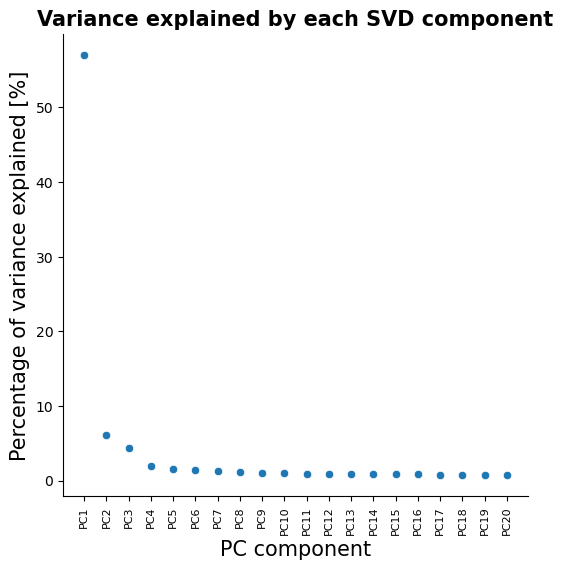

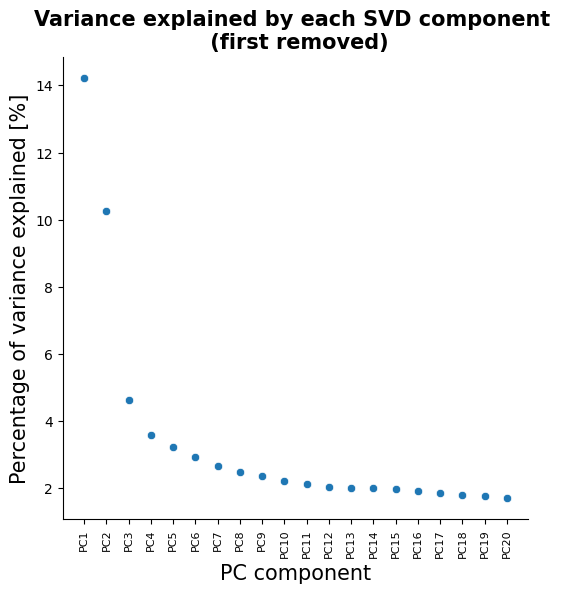

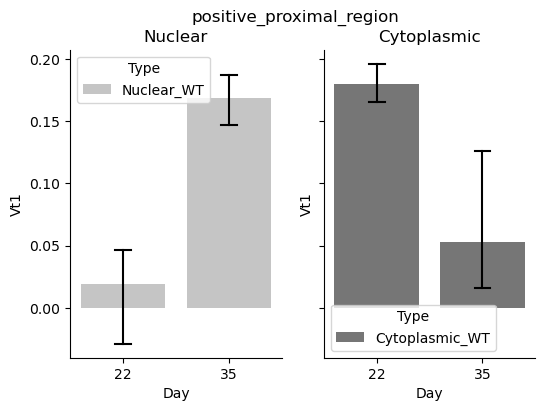

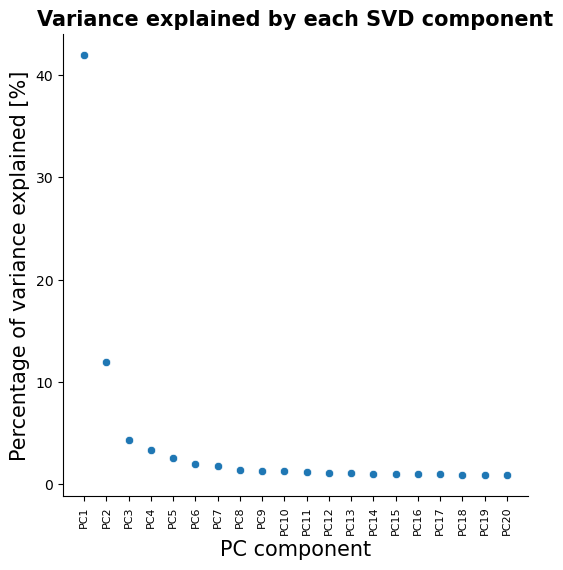

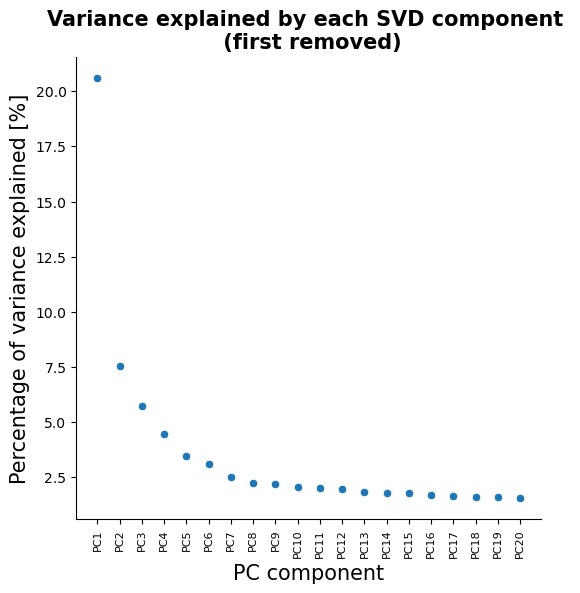

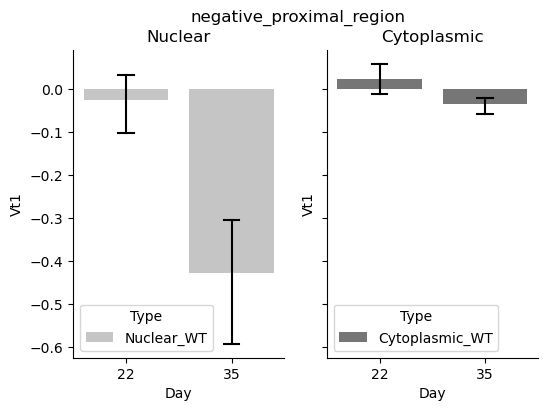

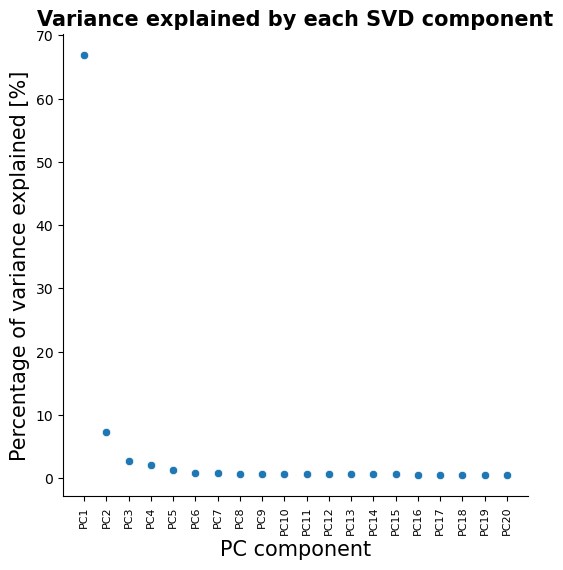

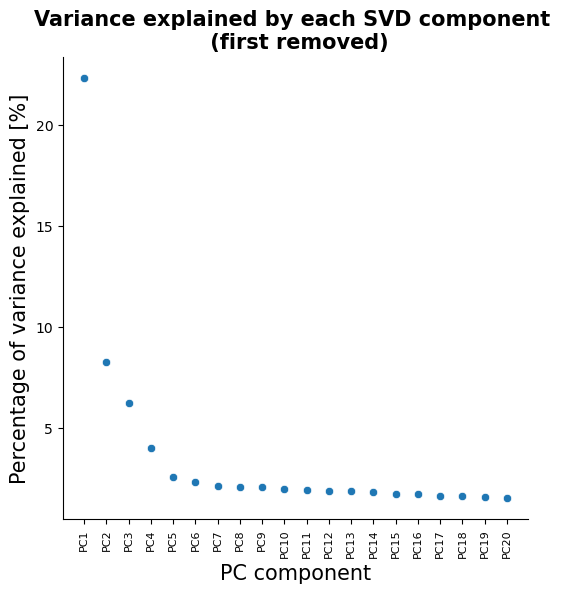

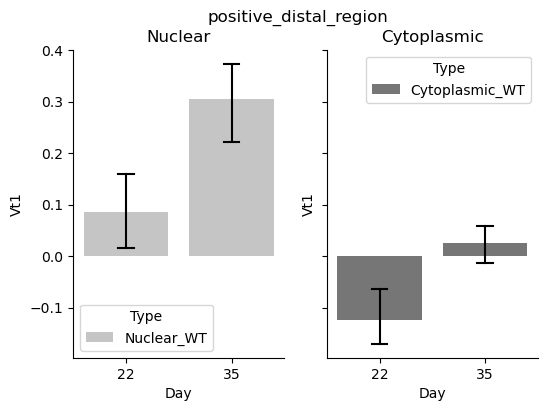

In [10]:
for region_name, region in zip(["positive_proximal_region", "negative_proximal_region", "positive_distal_region"], 
                               [positive_proximal_region, negative_proximal_region, positive_distal_region]):


    df_region = df[(df['dist'] >= region[0]) & (df['dist'] <= region[1]) & (df['Isoform'] == "Proximal 3'UTR Isoform")]
    df_int = df_region.loc[df_region.groupby(["Replicate", "Compartment", "CLIP", "VCP", "Day"])["mean_score_lg10"].idxmax()]
    # Create matrix with RBPs in rows and Compartment_VCP_Day combinations in columns
    df_int['Condition'] = df_int['Replicate'] + '_' + df_int['Compartment'] + '_' + df_int['VCP'] + '_' + df_int['Day']
    
    if region_name == "positive_proximal_region":
        df_int["mean_score_lg10"] = df_int["mean_score_lg10"].clip(lower=0)
        matrix = df_int.pivot(index='CLIP', columns='Condition', values='mean_score_lg10')

        
    elif region_name == "negative_proximal_region":
        # Negate first, then take the max: strongest depletion in the window
        df_region["mean_score_lg10"] = - df_region["mean_score_lg10"]
        df_int = df_region.loc[df_region.groupby(["Replicate", "Compartment", "CLIP", "VCP", "Day"])["mean_score_lg10"].idxmax()]
        df_int['Condition'] = df_int['Replicate'] + '_' + df_int['Compartment'] + '_' + df_int['VCP'] + '_' + df_int['Day']
        df_int["mean_score_lg10"] = df_int["mean_score_lg10"].clip(lower=0)
        matrix = df_int.pivot(index='CLIP', columns='Condition', values='mean_score_lg10')

    
    else:
        df_region = df[(df['dist'] >= region[0]) & (df['dist'] <= region[1]) & (df['Isoform'] == "Distal 3'UTR Isoform")]
        df_region["mean_score_lg10"] = -df_region["mean_score_lg10"]
        df_int = df_region.loc[df_region.groupby(["Replicate", "Compartment", "CLIP", "VCP", "Day"])["mean_score_lg10"].apply(lambda x: x.idxmax())]
        df_int['Condition'] = df_int['Replicate'] + '_' + df_int['Compartment'] + '_' + df_int['VCP'] + '_' + df_int['Day']
        df_int["mean_score_lg10"] = df_int["mean_score_lg10"].clip(lower=0)
        matrix = df_int.pivot(index='CLIP', columns='Condition', values='mean_score_lg10')

    print(f"Region: {region_name}, min: {matrix.min().min()}, max: {matrix.max().max()}")
    matrix_all_WT = matrix[[col for col in matrix.columns if "WT" in col]]


    U, s, Vt = svd(matrix_all_WT, full_matrices=True)


    explained_variance = s*100 / s.sum()

    df_var = pd.DataFrame(explained_variance, index=['PC'+str(i+1) for i in range(len(explained_variance))])[:20]

    plt.figure(figsize=(6, 6))
    sns.scatterplot(x=df_var.index, y=df_var[0])
    plt.xlabel('PC component', fontsize=15)
    plt.ylabel('Percentage of variance explained [%]', fontsize=15)
    plt.title('Variance explained by each SVD component', weight='bold', fontsize=15)
    sns.despine()
    plt.xticks(rotation=90, fontsize=8);
    plt.legend().remove()


    save_figure(f"{figures_subfolder}/Nuclear_and_Cytoplasmic_CTRL/scree_plot_{region_labels[region_name]}.pdf",
                legend=f"SVD of the per-patient Welch-score matrix (CLIP datasets x nuclear and cytoplasmic CTRL samples together (patients x days x fractions)) for {region_legends[region_name]}, scores clipped at 0. The matrix is not centred, so the first component (mostly the mean binding level) is removed and the SVD redone on the residual; 'PC1/Vt1' after removal = component 2 of the original SVD. Scree plot: share of each singular value in the sum of singular values (s_i / sum(s), first 20 components), before removing the first component.")
    ## Removing first component
    X_without_PC1 = matrix_all_WT - np.dot(np.array([U[:, 0]*s[0]]).T, np.array([Vt[0]]))

    # Do the SVD again
    U_w1, s_w1, Vt_w1 = svd(X_without_PC1, full_matrices=False)

    explained_variance_w1 = s_w1*100 / s_w1.sum()
    df_var_w1 = pd.DataFrame(explained_variance_w1, index=['PC'+str(i+1) for i in range(len(explained_variance_w1))])[:20]
    plt.figure(figsize=(6, 6))
    sns.scatterplot(x=df_var_w1.index, y=df_var_w1[0])
    plt.xlabel('PC component', fontsize=15)
    plt.ylabel('Percentage of variance explained [%]', fontsize=15)
    plt.title('Variance explained by each SVD component \n (first removed)', weight='bold', fontsize=15)
    sns.despine()
    plt.xticks(rotation=90, fontsize=8);
    plt.legend().remove()
    save_figure(f"{figures_subfolder}/Nuclear_and_Cytoplasmic_CTRL/scree_plot_{region_labels[region_name]}_first_component_removed.pdf",
                legend=f"SVD of the per-patient Welch-score matrix (CLIP datasets x nuclear and cytoplasmic CTRL samples together (patients x days x fractions)) for {region_legends[region_name]}, scores clipped at 0. The matrix is not centred, so the first component (mostly the mean binding level) is removed and the SVD redone on the residual; 'PC1/Vt1' after removal = component 2 of the original SVD. Scree plot: share of each singular value in the sum of singular values (s_i / sum(s), first 20 components), after removing the first component.")

    elbow_idx, distances = find_elbow(explained_variance)
    elbow_idx_w1, distances_w1 = find_elbow(explained_variance_w1)
    n_pcs = elbow_idx_w1 + 1

    df_pca = pd.DataFrame((U_w1[:, :len(s_w1)] * s_w1)[:, :len(s_w1)], index=matrix_all_WT.index, columns=['PC'+str(i+1) for i in range(len(s_w1))])
    ordered_columns = sorted(matrix_all_WT.columns, key=sort_key)
    df_pca = df_pca.merge(matrix_all_WT[ordered_columns], left_index=True, right_index=True)


    df_Vt = pd.DataFrame(Vt_w1.T, index=matrix_all_WT.columns, columns=['Vt'+str(i+1) for i in range(Vt_w1.shape[0])])

    df_Vt['Mutation'] = df_Vt.index.str.split('_').str[2]
    df_Vt['Day'] = df_Vt.index.str.split('_D').str[1]
    df_Vt['Day'] = df_Vt['Day'].astype(int)
    df_Vt['Compartment'] = df_Vt.index.str.split('_').str[1]
    df_Vt['Type'] = df_Vt['Compartment'] + '_' + df_Vt['Mutation']


    df_Vt_diff = df_Vt.copy()
    df_Vt_diff['patient'] = df_Vt_diff.index.str.split('_').str[0]

    vt_cols = [col for col in df_Vt.columns if col.startswith('Vt')]

    df_Vt_diff = df_Vt.copy()
    df_Vt_diff['Patient'] = df_Vt_diff.index.str.split('_').str[0]

    # Sort by patient and day so diff() computes consecutive-day differences
    df_Vt_diff = df_Vt_diff.sort_values(['Patient', 'Day'])

    df_Vt_diff_Nuc = df_Vt_diff[df_Vt_diff['Compartment'] == 'Nuclear'].copy()
    df_Vt_diff_Cyto = df_Vt_diff[df_Vt_diff['Compartment'] == 'Cytoplasmic'].copy()



    # D3-D0, D7-D3, D14-D7, D22-D14, D35-D22 (D0 becomes NaN)
    df_Vt_diff_Nuc[vt_cols] = df_Vt_diff_Nuc.groupby('Patient')[vt_cols].diff()
    df_Vt_diff_Nuc = df_Vt_diff_Nuc[df_Vt_diff_Nuc['Day'].isin([22, 35])]


    fig, ax = plt.subplots(1, 2, figsize=(6, 4), sharey=True)

    sns.barplot(
        data=df_Vt_diff_Nuc,
        x='Day',
        y='Vt1',
        hue='Type',
        palette=palette_condition,
                    capsize=0.15,
                errcolor="black",
                errwidth=1.5,
    ax=ax[0]
    )
    sns.despine()
    ax[0].set_title(f"Nuclear")

    # D3-D0, D7-D3, D14-D7, D22-D14, D35-D22 (D0 becomes NaN)
    df_Vt_diff_Cyto[vt_cols] = df_Vt_diff_Cyto.groupby('Patient')[vt_cols].diff()
    df_Vt_diff_Cyto = df_Vt_diff_Cyto[df_Vt_diff_Cyto['Day'].isin([22, 35])]
    sns.barplot(
        data=df_Vt_diff_Cyto,
        x='Day',
        y='Vt1',
        hue='Type',
        palette=palette_condition,
                    capsize=0.15,
                errcolor="black",
                errwidth=1.5,
                ax=ax[1]

    )
    sns.despine()
    ax[1].set_title(f"Cytoplasmic")
    plt.suptitle(region_name)
    save_figure(f"{figures_subfolder}/Nuclear_and_Cytoplasmic_CTRL/component1_change_D14_to_D22_and_D22_to_D35_{region_labels[region_name]}.pdf",
                legend=f"SVD of the per-patient Welch-score matrix (CLIP datasets x nuclear and cytoplasmic CTRL samples together (patients x days x fractions)) for {region_legends[region_name]}, scores clipped at 0. The matrix is not centred, so the first component (mostly the mean binding level) is removed and the SVD redone on the residual; 'PC1/Vt1' after removal = component 2 of the original SVD. Change of the first residual component (Vt1) from the previous day for each patient, "
                       "computed within each fraction: D22 - D14 (bars at D22) and D35 - D22 (bars at D35), nuclear (left) "
                       "and cytoplasmic (right) panels; mean and 95% CI across patients. No statistical test.")

    